# Site Selection
Builds `regions.parquet` (used by main.py to download gee data) and `labels.parquet` (used by corals_dataset_builder.py as ground truth) from Reef Check Belt.csv.
A subset of the data (N_SITES = 12) is used for local code development purposes. The full dataset (N_SITES = "all") in Indo-Pacific region is used to create the final `labels.parquet` file.
Uses % of Population Bleaching, S1-S4 is averaged 

Run this notebook in local venv, bc required belt.csv not included in git, therefore not in docker

In [108]:
import pandas as pd



N_SITES = "all"
REGION = "all" 
SEVERE_BLEACHING_THRESHOLD = 0
MIN_LABEL_QUARTERS = 0 #test if better results if very dominant 1 labeled quarter sites are excluded
START_QUARTER = "2017-04-01"
END_QUARTER = "2026-08-01"
SEGMENT_COLUMNS = ["s1 (0-20m)", "s2 (25-45m)", "s3 (50-70m)", "s4 (75-95m)"]

belt = pd.read_csv(r"C:\Users\ohlle\OneDrive\Dokumente\TUM\Master\Research Practice\Scripts\Labels\Belt.csv")


In [109]:
df_belt = pd.DataFrame(belt)
df_belt.head()
pd.set_option("display.max_columns", None)
pd.set_option("display.width", None)

print(df_belt.shape)
df_belt.head()

(678948, 30)


,site_id,survey_id,static_descriptors_reef_id (archived field),reef_name,coordinates_in_decimal_degree_format,longitude_degrees,longitude_minutes,longitude_seconds,longitude_cardinal_direction,latitude_degrees,latitude_minutes,latitude_seconds,latitude_cardinal_direction,country,state_province_island,city_town,region,year,date,depth (m),organism_code,type,s1 (0-20m),s2 (25-45m),s3 (50-70m),s4 (75-95m),fish_recorded_by,inverts_recorded_by,errors,what_errors
0,6a8719bb-91fe-46c1-9635-37fb1f022ea9,000887f9-b8c4-4c43-bc63-700c0e8b385b,119.18.33.5E.11.0.57.5N,Masigasig/Esteban Reef,"11.015972, 119.309306",119,18,33.5,E,11,0,57.5,N,Philippines,Palawan,Taytay,Indo-Pacific,2016,20-April-16,3.0,Butterflyfish,Fish,6,10,12,0,NaN,NaN,False,NaN
1,6a8719bb-91fe-46c1-9635-37fb1f022ea9,000887f9-b8c4-4c43-bc63-700c0e8b385b,119.18.33.5E.11.0.57.5N,Masigasig/Esteban Reef,"11.015972, 119.309306",119,18,33.5,E,11,0,57.5,N,Philippines,Palawan,Taytay,Indo-Pacific,2016,20-April-16,3.0,Haemulidae,Fish,0,1,0,0,NaN,NaN,False,NaN
2,6a8719bb-91fe-46c1-9635-37fb1f022ea9,000887f9-b8c4-4c43-bc63-700c0e8b385b,119.18.33.5E.11.0.57.5N,Masigasig/Esteban Reef,"11.015972, 119.309306",119,18,33.5,E,11,0,57.5,N,Philippines,Palawan,Taytay,Indo-Pacific,2016,20-April-16,3.0,Snapper,Fish,2,0,2,2,NaN,NaN,False,NaN
3,6a8719bb-91fe-46c1-9635-37fb1f022ea9,000887f9-b8c4-4c43-bc63-700c0e8b385b,119.18.33.5E.11.0.57.5N,Masigasig/Esteban Reef,"11.015972, 119.309306",119,18,33.5,E,11,0,57.5,N,Philippines,Palawan,Taytay,Indo-Pacific,2016,20-April-16,3.0,Barramundi Cod,Fish,0,0,0,0,NaN,NaN,False,NaN
4,6a8719bb-91fe-46c1-9635-37fb1f022ea9,000887f9-b8c4-4c43-bc63-700c0e8b385b,119.18.33.5E.11.0.57.5N,Masigasig/Esteban Reef,"11.015972, 119.309306",119,18,33.5,E,11,0,57.5,N,Philippines,Palawan,Taytay,Indo-Pacific,2016,20-April-16,3.0,Humphead Wrasse,Fish,0,0,0,0,NaN,NaN,False,NaN


## Bleaching Sum and Formatting

In [110]:
belt[SEGMENT_COLUMNS] = belt[SEGMENT_COLUMNS].apply(pd.to_numeric, errors="coerce") # blanks in s1-s4 ->NaN
pop = belt[belt["organism_code"] == "Bleaching (% Of Population)"].copy() # extract bleaching
pop["bleaching_percent"] = pop[SEGMENT_COLUMNS].mean(axis=1, skipna=True) # average s1-s4, ignore blanks

pop["date"] = pd.to_datetime(pop["date"], errors="coerce")
pop["quarter"] = pop["date"].dt.to_period("Q").dt.start_time # converts survey dates to quarter

coords = pop["coordinates_in_decimal_degree_format"].astype(str).str.split(",", expand=True) # split longitude, latitude
pop["lat"] = pd.to_numeric(coords[0].str.strip(), errors="coerce")
pop["lon"] = pd.to_numeric(coords[1].str.strip(), errors="coerce")

print(pop.shape)
pop.head()

C:\Users\ohlle\AppData\Local\Temp\ipykernel_21936\3923164910.py:5: UserWarning: Could not infer format, so each element will be parsed individually, falling back to `dateutil`. To ensure parsing is consistent and as-expected, please specify a format.
  pop["date"] = pd.to_datetime(pop["date"], errors="coerce")


(16949, 34)


,site_id,survey_id,static_descriptors_reef_id (archived field),reef_name,coordinates_in_decimal_degree_format,longitude_degrees,longitude_minutes,longitude_seconds,longitude_cardinal_direction,latitude_degrees,latitude_minutes,latitude_seconds,latitude_cardinal_direction,country,state_province_island,city_town,region,year,date,depth (m),organism_code,type,s1 (0-20m),s2 (25-45m),s3 (50-70m),s4 (75-95m),fish_recorded_by,inverts_recorded_by,errors,what_errors,bleaching_percent,quarter,lat,lon
33,6a8719bb-91fe-46c1-9635-37fb1f022ea9,000887f9-b8c4-4c43-bc63-700c0e8b385b,119.18.33.5E.11.0.57.5N,Masigasig/Esteban Reef,"11.015972, 119.309306",119,18,33.5,E,11,0,57.5,N,Philippines,Palawan,Taytay,Indo-Pacific,2016,2016-04-20,3.0,Bleaching (% Of Population),Impact,0.0,0.0,0.0,0.0,NaN,NaN,False,NaN,0.00,2016-04-01,11.015972,119.309306
73,165deb2d-692c-49c9-889d-7ce5c6156657,00103835-7d8a-4099-a58b-bac77e8e81bc,129.57.21.3E.4.32.59.2S,Banda Besar 4.55,"-4.549778, 129.955917",129,57,21.3,E,4,32,59.2,S,Indonesia,Maluku Tengah,Banda Naira,Indo-Pacific,2018,2018-12-08,10.0,Bleaching (% Of Population),Impact,0.0,0.0,0.0,0.0,"Carolina Menze, Emil Sjahman","Carolina Menze, Emil Sjahman",False,NaN,0.00,2018-10-01,-4.549778,129.955917
113,35a4fe9c-76e0-4961-a0eb-0953acf2dc7e,0016ef4b-d18c-4ace-a821-ec622688a708,124.40.11.3E.10.30.57.9N,Mahaba Marine Sanctuary,"10.516083, 124.669806",124,40,11.3,E,10,30,57.9,N,Philippines,Leyte,Inopacan Municipality,Indo-Pacific,2008,2008-07-24,12.0,Bleaching (% Of Population),Impact,0.0,0.0,0.0,0.0,NaN,NaN,False,NaN,0.00,2008-07-01,10.516083,124.669806
153,ba897ac0-d2e4-453c-946c-934f8b9ba838,001a09e0-e52f-4adf-bb2d-e66e2bacb3b5,151.47.2.3W.16.29.57.9S,Tapu (external slope),"-16.499417, -151.783972",151,47,2.3,W,16,29,57.9,S,French Polynesia,NaN,Bora Bora,Indo-Pacific,2014,2014-10-19,7.0,Bleaching (% Of Population),Impact,0.0,0.0,0.0,0.0,NaN,NaN,False,NaN,0.00,2014-10-01,-16.499417,-151.783972
193,9067f611-93bd-4e0b-97cc-94d9b4ec4266,001adbf1-e2eb-4ef7-b600-bd8a923e0020,103.57.36.1E.2.32.54.8N,Pulau Mensirip Transect 2,"2.548556, 103.960028",103,57,36.1,E,2,32,54.8,N,Malaysia,Johor,Mersing,Indo-Pacific,2022,2022-08-23,5.2,Bleaching (% Of Population),Impact,0.0,0.0,0.0,1.0,"Izzat bin A'rizu, SIVA PRAKASH A/L ARIKRISHNAN",SIVA PRAKASH A/L ARIKRISHNAN,NaN,NaN,0.25,2022-07-01,2.548556,103.960028


In [111]:
pop = pop.dropna(subset=["site_id", "quarter", "bleaching_percent", "lat", "lon"]) #remove rows with missing values
pop.shape

(14512, 34)

In [112]:
time_index = pd.date_range(START_QUARTER, END_QUARTER, freq="QS") # dates expected by existing scripts
pop = pop[pop["quarter"].isin(time_index)].copy() # keep only data in time range
pop.shape

(5127, 34)

In [113]:
site_id_counts_per_region = (
    pop.groupby("region")["site_id"]
    .nunique()
    .sort_values(ascending=False)
    .to_frame()
    .T
)

site_id_counts_per_region.index = ["n_site_ids"]
site_id_counts_per_region

region,Indo-Pacific,Atlantic,Hawaii,Red Sea,Arabian Gulf,East Pacific
n_site_ids,1063,196,64,48,6,1


In [114]:
# check reef depth variation
shallow_reefs = (
    pop.loc[
        pop["depth (m)"] < 15,
        ["site_id", "depth (m)", "date", "reef_name", "bleaching_percent", "lat", "lon"],
    ]
    .sort_values("site_id")
)

site_observation_counts = shallow_reefs.groupby("site_id").size()
sites_with_enough_observations = site_observation_counts[site_observation_counts >= 4].index

shallow_reefs = shallow_reefs[shallow_reefs["site_id"].isin(sites_with_enough_observations)].copy()
shallow_reefs = shallow_reefs.sort_values(["site_id", "date"])
shallow_reefs.head(20)

,site_id,depth (m),date,reef_name,bleaching_percent,lat,lon
524934,0098fca8-d6c6-4859-ba06-74d5207a44ca,8.3,2018-11-21,Twin Peaks,0.00,10.121028,99.834861
228475,0098fca8-d6c6-4859-ba06-74d5207a44ca,5.0,2018-11-21,Twin Peaks,2.75,10.121028,99.834861
455125,0098fca8-d6c6-4859-ba06-74d5207a44ca,9.5,2020-12-17,Twin Peaks,0.00,10.121028,99.834861
290041,0098fca8-d6c6-4859-ba06-74d5207a44ca,5.0,2020-12-17,Twin Peaks,0.00,10.121028,99.834861
621069,0098fca8-d6c6-4859-ba06-74d5207a44ca,8.3,2021-03-18,Twin Peaks,0.00,10.121028,99.834861
31389,0098fca8-d6c6-4859-ba06-74d5207a44ca,5.0,2021-03-18,Twin Peaks,0.00,10.121028,99.834861
3858,0098fca8-d6c6-4859-ba06-74d5207a44ca,3.0,2021-06-03,Twin Peaks,0.00,10.121028,99.834861
597619,0098fca8-d6c6-4859-ba06-74d5207a44ca,8.0,2021-06-03,Twin Peaks,2.50,10.121028,99.834861
507111,0129d04a-00f3-4847-a0cc-bbc90dcc9813,10.0,2023-09-27,Matthew's Reef,52.50,18.365951,-68.848883
457938,0129d04a-00f3-4847-a0cc-bbc90dcc9813,10.0,2024-02-29,Matthew's Reef,0.00,18.365951,-68.848883


## Sort severe bleaching sites based on label coverage

For the 12 site subset the dataset was previously sorted, to have sites with severe bleaching included

In [115]:
labels_long = pop.groupby(["site_id", "quarter"], as_index=False).agg(bleaching_percent=("bleaching_percent", "mean")) # average if site has more than one survey in the same quarter

site_info = (
    pop.sort_values("date")
    .groupby("site_id", as_index=False)
    .agg(
        reef_name=("reef_name", "first"),
        region=("region", "first"),
        country=("country", "first"),
        lat=("lat", "first"),
        lon=("lon", "first"),
        depth=("depth (m)", "first"),
    )
) # collect one coordinate and name per site

site_stats = (
    labels_long.groupby("site_id", as_index=False)
    .agg(
        n_label_quarters=("quarter", "nunique"),
        max_pop_bleaching=("bleaching_percent", "max"),
        min_pop_bleaching=("bleaching_percent", "min"),
    )
)


candidates = site_info.merge(site_stats, on="site_id", how="inner")
candidates = candidates[
    (candidates["max_pop_bleaching"] >= SEVERE_BLEACHING_THRESHOLD)
    & (candidates["n_label_quarters"] >= MIN_LABEL_QUARTERS)
].copy() 
if REGION != "all":
    candidates = candidates[candidates["region"] == REGION].copy()

candidates = candidates.sort_values(["n_label_quarters", "max_pop_bleaching"], ascending=[False, False]).copy()

candidates.head(12)


,site_id,reef_name,region,country,lat,lon,depth,n_label_quarters,max_pop_bleaching,min_pop_bleaching
1040,c4078dab-0617-498d-ab57-b01bbbc7d2b1,Halik,Indo-Pacific,Indonesia,-8.337639,116.037639,4.0,27,14.375,0.0
276,34c918c4-48dc-4a17-b06a-e40f8d77452f,Povai,Indo-Pacific,French Polynesia,-16.542694,-151.740778,2.0,17,100.000,0.0
175,20a3d1cd-cc36-4ecb-a07a-42783c335549,Motu Haapiti,Indo-Pacific,French Polynesia,-16.457028,-151.775806,1.0,17,31.500,0.0
507,5fbe3716-08f8-4eb1-86ea-c0fe7ae7465e,Motu Tane,Indo-Pacific,French Polynesia,-16.448056,-151.765889,1.3,17,30.250,0.0
758,8f2a090d-9f8e-49b5-a749-b6e64f7f4902,Sofitel Motu,Indo-Pacific,French Polynesia,-16.535278,-151.728444,1.2,17,20.000,0.0
225,29917b4f-ee50-4d06-ba50-3729ba030462,Jardin de Corail (Coral Garden),Indo-Pacific,French Polynesia,-16.549056,-151.703778,1.0,17,16.250,0.0
995,ba897ac0-d2e4-453c-946c-934f8b9ba838,Tapu (external slope),Indo-Pacific,French Polynesia,-16.499417,-151.783972,15.0,17,15.000,0.0
1103,d0bdbae0-3ea3-4675-ab5a-c2f6fff2f193,Matira,Indo-Pacific,French Polynesia,-16.552583,-151.732556,1.0,17,2.500,0.0
1264,ec034f46-ec6d-42ce-b662-b4f874c59f45,Revatua (fringing reef),Indo-Pacific,French Polynesia,-16.479556,-151.720389,1.0,16,39.500,0.0
186,22f8a34a-19f1-4694-9473-fd015c6d9fbe,Motu Tapu,Indo-Pacific,French Polynesia,-16.506417,-151.783611,1.0,16,39.000,0.0


## regions.parquet (used by main.py to download gee data)

In [116]:
# if for training purposes N_SITES is limited, the sorted candidates will be randomly sampled
SPATIAL_SITE_SELECTION_SEED = 42

if N_SITES == "all":
    selected = candidates.sort_values("site_id").copy()
else:
    selected = (
        candidates
        .sort_values("site_id")
        .sample(n=N_SITES, random_state=SPATIAL_SITE_SELECTION_SEED)
        .sort_values("site_id")
        .copy()
    )
   

In [ ]:
###########only temporary for testcornfiles and testsentinel creation############## ->omment out before docker!!
#selected = (
#    candidates
#    .head(N_SITES)
#    .sort_values("site_id")
#    .copy()
#)

In [117]:
 
selected_site_ids = selected["site_id"].tolist()

regions = selected[["site_id", "lat", "lon"]]
regions = regions.rename(columns={"site_id": "Site_ID"}) # bc main.py expects
regions.to_parquet(r"C:\Users\ohlle\OneDrive\Dokumente\TUM\Master\Research Practice\Scripts\Labels\regions.parquet", index=False)
regions.head(12)

,Site_ID,lat,lon
0,0098fca8-d6c6-4859-ba06-74d5207a44ca,10.121028,99.834861
1,009b5024-f412-4606-b016-497c0eb48ae2,-8.340278,116.028611
2,00ab83f6-ad6e-4b56-86c8-971a8abcc19d,19.643667,-156.015667
3,00b56bab-1879-4d7d-bbc7-f5ae3ce3d541,22.829722,121.188889
4,0129d04a-00f3-4847-a0cc-bbc90dcc9813,18.365951,-68.848883
5,0155a127-73ba-44ff-817f-7343b05f8c7f,-8.676667,115.520278
6,017b73b2-2567-44c8-ad06-fb703941fd05,2.218306,104.149833
7,01a8ff52-ee72-4576-924b-1819ba49eda8,-16.765861,179.964472
8,01c91a51-8bfa-450e-b174-7a3555e08d21,19.690417,-156.039417
9,025087b9-09e6-4978-a3de-44d78cd70b7f,11.338389,-60.550028


In [118]:
regions.shape

(1378, 3)

In [119]:
selected_labels_long = labels_long[labels_long["site_id"].isin(selected_site_ids)].copy()
selected_labels_long["sid"] = "SID_" + selected_labels_long["site_id"].astype(str) # SID_x like in exisiting scripts
labels = selected_labels_long.pivot(index="sid", columns="quarter", values="bleaching_percent").reindex(columns=time_index)
labels = labels.reindex(index=["SID_" + str(site_id) for site_id in selected_site_ids]) #order
labels.to_parquet(r"C:\Users\ohlle\OneDrive\Dokumente\TUM\Master\Research Practice\Scripts\Labels\labels.parquet")
labels.head(12) # NaN's for quarters without survey data->ignored in train.py

,2017-04-01,2017-07-01,2017-10-01,2018-01-01,2018-04-01,2018-07-01,2018-10-01,2019-01-01,2019-04-01,2019-07-01,2019-10-01,2020-01-01,2020-04-01,2020-07-01,2020-10-01,2021-01-01,2021-04-01,2021-07-01,2021-10-01,2022-01-01,2022-04-01,2022-07-01,2022-10-01,2023-01-01,2023-04-01,2023-07-01,2023-10-01,2024-01-01,2024-04-01,2024-07-01,2024-10-01,2025-01-01,2025-04-01,2025-07-01,2025-10-01,2026-01-01,2026-04-01,2026-07-01
sid,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,
SID_0098fca8-d6c6-4859-ba06-74d5207a44ca,NaN,NaN,NaN,NaN,NaN,NaN,1.375,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.0,0.0,1.25,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
SID_009b5024-f412-4606-b016-497c0eb48ae2,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.0,0.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
SID_00ab83f6-ad6e-4b56-86c8-971a8abcc19d,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.0,NaN,NaN,NaN,NaN,NaN,NaN
SID_00b56bab-1879-4d7d-bbc7-f5ae3ce3d541,NaN,0.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
SID_0129d04a-00f3-4847-a0cc-bbc90dcc9813,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,52.5,NaN,0.0,0.0,0.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
SID_0155a127-73ba-44ff-817f-7343b05f8c7f,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,1.25,NaN,NaN,NaN,NaN
SID_017b73b2-2567-44c8-ad06-fb703941fd05,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.5,NaN,0.0,NaN,NaN,NaN,0.75,NaN,NaN,NaN,NaN,0.0,NaN,NaN,NaN,0.0,NaN,NaN,NaN,NaN,NaN
SID_01a8ff52-ee72-4576-924b-1819ba49eda8,NaN,NaN,NaN,NaN,0.0,NaN,NaN,0.125,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
SID_01c91a51-8bfa-450e-b174-7a3555e08d21,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.0,NaN,NaN,NaN,NaN,NaN,NaN


### Convert from percentages to ordinal classes

This section was added to change the project to ordinal classification

- `0`: none, `[0, 1)` percent
- `1`: low, `[1, 10)` percent
- `2`: moderate, `[10, 50]` percent
- `3`: severe, `(50, 100]` percent

In [121]:
def bleaching_percent_to_class(value):
    # Preserve missing quarters.
    if pd.isna(value):
        return float("nan")
    if value < 1:
        return 0.0
    if value < 10:
        return 1.0
    if value <= 50:
        return 2.0
    return 3.0

labels = labels.map(bleaching_percent_to_class).astype("float32")

labels.to_parquet(
    r"C:\Users\ohlle\OneDrive\Dokumente\TUM\Master\Research Practice\Scripts\Labels\labels.parquet"
)
print("number of quarters per class:")
print(labels.stack().value_counts().sort_index()) #number of quarters per class

labels.head()

number of quarters per class:
0.0    3055
1.0     984
2.0     330
3.0      46
Name: count, dtype: int64


,2017-04-01,2017-07-01,2017-10-01,2018-01-01,2018-04-01,2018-07-01,2018-10-01,2019-01-01,2019-04-01,2019-07-01,2019-10-01,2020-01-01,2020-04-01,2020-07-01,2020-10-01,2021-01-01,2021-04-01,2021-07-01,2021-10-01,2022-01-01,2022-04-01,2022-07-01,2022-10-01,2023-01-01,2023-04-01,2023-07-01,2023-10-01,2024-01-01,2024-04-01,2024-07-01,2024-10-01,2025-01-01,2025-04-01,2025-07-01,2025-10-01,2026-01-01,2026-04-01,2026-07-01
sid,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,
SID_0098fca8-d6c6-4859-ba06-74d5207a44ca,NaN,NaN,NaN,NaN,NaN,NaN,1.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.0,0.0,1.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
SID_009b5024-f412-4606-b016-497c0eb48ae2,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.0,0.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
SID_00ab83f6-ad6e-4b56-86c8-971a8abcc19d,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.0,NaN,NaN,NaN,NaN,NaN,NaN
SID_00b56bab-1879-4d7d-bbc7-f5ae3ce3d541,NaN,0.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
SID_0129d04a-00f3-4847-a0cc-bbc90dcc9813,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,3.0,NaN,0.0,0.0,0.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [122]:
# check how many sites there are that only conatin majority class 0 or NaN -> undersampling test
pure_class_0 = labels.fillna(0).eq(0).all(axis=1)

print(f"Class-0/NaN-only sites: {pure_class_0.sum()}")
print(labels.index[pure_class_0].tolist())

Class-0/NaN-only sites: 621
['SID_009b5024-f412-4606-b016-497c0eb48ae2', 'SID_00ab83f6-ad6e-4b56-86c8-971a8abcc19d', 'SID_00b56bab-1879-4d7d-bbc7-f5ae3ce3d541', 'SID_017b73b2-2567-44c8-ad06-fb703941fd05', 'SID_01a8ff52-ee72-4576-924b-1819ba49eda8', 'SID_01c91a51-8bfa-450e-b174-7a3555e08d21', 'SID_02590aa5-fa5f-4ac1-809e-1cfb2bb44787', 'SID_025ba59a-2cea-4842-8297-882ca557d376', 'SID_02a685bf-215f-490a-aa41-9099c9d30dfb', 'SID_02ec8ece-2d6d-4dc0-80bf-8a39f3269027', 'SID_03c8f40d-dfa6-49a8-a423-847f96c640c5', 'SID_04864400-315b-4ba7-bcad-7d9ffe91f487', 'SID_05215adf-f4f8-4857-80bb-d8fb8a57100a', 'SID_05370027-e0d8-4e71-b5f8-e36c7a75ee68', 'SID_057e0970-76af-4fb8-8341-d9a3f8e7d7c0', 'SID_05a79082-0911-4f7d-b49a-8125490bc944', 'SID_07fad98b-01e2-4751-8b3f-dd61795bf229', 'SID_0803c28c-547d-47e9-b44d-b45caf6b5015', 'SID_0898237a-dd82-4a73-af0b-9e7449ab8875', 'SID_0954ee7a-9e64-4b6b-a09c-3d3e4391b749', 'SID_09e70f59-e639-4ac3-9bfa-a7e9d13cf354', 'SID_0a1621f6-6557-4199-a5c2-881de8de29ea', 'SI

In [123]:
labels.shape # format: (sites, quarters)

(1378, 38)

In [124]:
labels.index.is_unique

True

In [125]:
regions["Site_ID"].is_unique

True

# Site-level Spatial Split 
Builds `splits.parquet`: sites are grouped into spatial blocks (nearby reefs stay together) and whole blocks are assigned to train/val/test with a fixed random seed. Sets are balanced on the distribution of the four actual classification classes (0: none, 1: low, 2: moderate, 3: severe).

## Visualization of data
Previously split was balanced on number of labeled quarters and number of severe bleaching, code was kept for visualization

In [126]:
spatial_selected = selected.copy()
spatial_selected_site_ids = selected_site_ids

In [127]:
# count number of labeled quarters and number of severe bleaching (>10%) quarters per site
import numpy as np

SPLIT_RANDOM_SEED = 42       
SPATIAL_BLOCK_DEG = 1        # degree size of one spatial block 
SEVERE_QUARTER_THRESHOLD = 10  # quarter is severe if > threshold
SPLIT_TARGET_FRACTIONS = {"train": 0.70, "val": 0.15, "test": 0.15} 


split_labels_long = labels_long[labels_long["site_id"].isin(spatial_selected_site_ids)].copy()
split_labels_long["is_severe_quarter"] = split_labels_long["bleaching_percent"] >= SEVERE_QUARTER_THRESHOLD

site_severity = split_labels_long.groupby("site_id").agg(
    n_label_quarters=("quarter", "nunique"),
    n_severe_bleaching=("is_severe_quarter", "sum"),
)

split_sites = spatial_selected[["site_id", "lat", "lon"]].merge(site_severity, on="site_id", how="left")
split_sites.head(10)

,site_id,lat,lon,n_label_quarters,n_severe_bleaching
0,0098fca8-d6c6-4859-ba06-74d5207a44ca,10.121028,99.834861,4,0
1,009b5024-f412-4606-b016-497c0eb48ae2,-8.340278,116.028611,2,0
2,00ab83f6-ad6e-4b56-86c8-971a8abcc19d,19.643667,-156.015667,1,0
3,00b56bab-1879-4d7d-bbc7-f5ae3ce3d541,22.829722,121.188889,1,0
4,0129d04a-00f3-4847-a0cc-bbc90dcc9813,18.365951,-68.848883,4,1
5,0155a127-73ba-44ff-817f-7343b05f8c7f,-8.676667,115.520278,1,0
6,017b73b2-2567-44c8-ad06-fb703941fd05,2.218306,104.149833,5,0
7,01a8ff52-ee72-4576-924b-1819ba49eda8,-16.765861,179.964472,2,0
8,01c91a51-8bfa-450e-b174-7a3555e08d21,19.690417,-156.039417,1,0
9,025087b9-09e6-4978-a3de-44d78cd70b7f,11.338389,-60.550028,4,0


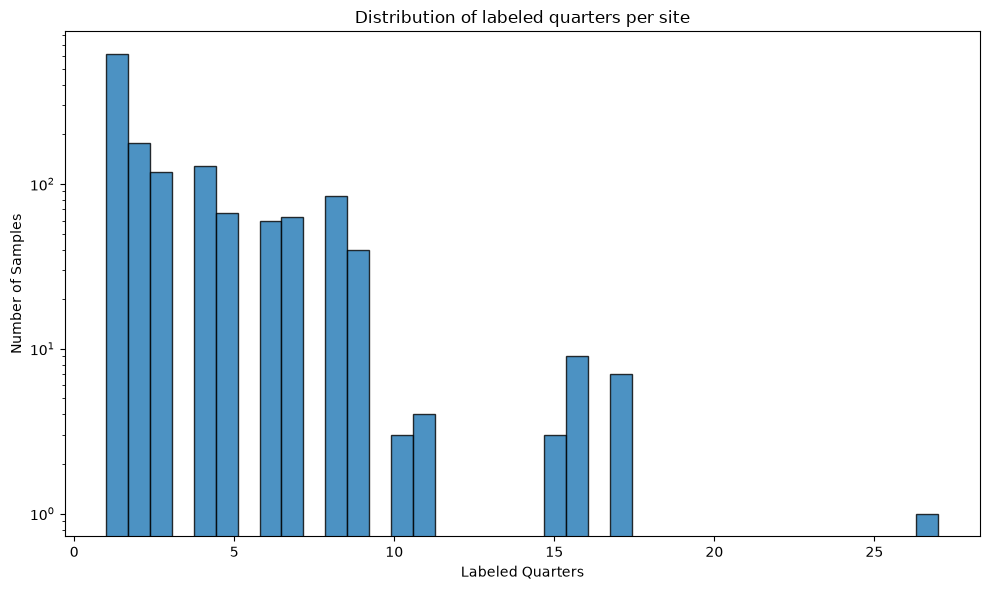

In [128]:
from matplotlib import pyplot as plt
ax = split_sites["n_label_quarters"].plot(
    kind="hist",
    bins=38,                # 38 quarters max (in all pacific dataset)
    figsize=(10, 6),
    edgecolor="black",
    alpha=0.8
)

plt.yscale("log")  
ax.set_title("Distribution of labeled quarters per site")
ax.set_xlabel("Labeled Quarters")
ax.set_ylabel("Number of Samples")

plt.tight_layout()
plt.show()


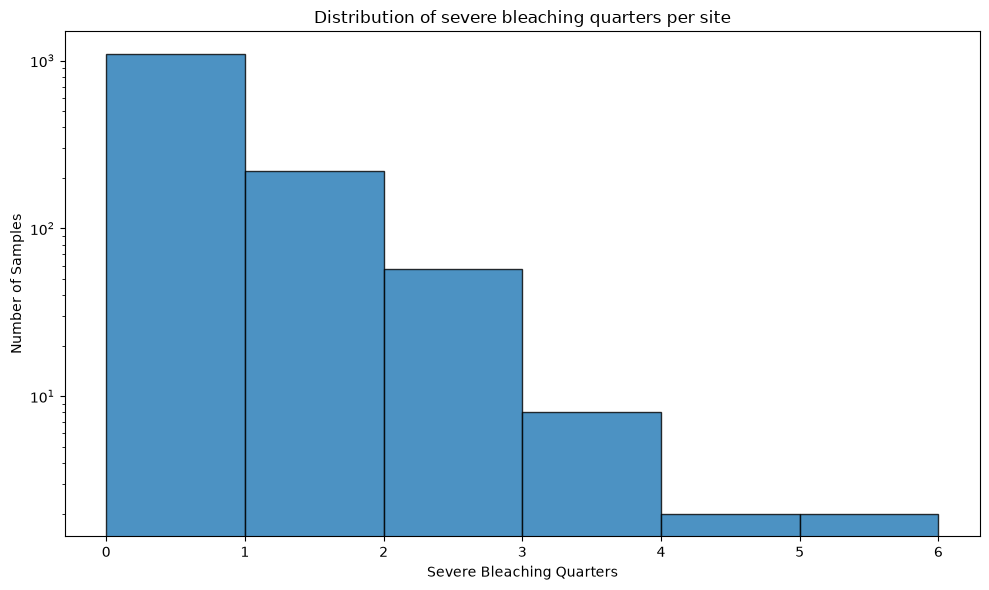

In [ ]:
ax = split_sites["n_severe_bleaching"].plot(
    kind="hist",
    bins=6,                # 6 quarters max (in all pacific dataset)
    figsize=(10, 6),
    edgecolor="black",
    alpha=0.8
)

plt.yscale("log")  
ax.set_title("Distribution of severe bleaching quarters per site")
ax.set_xlabel("Severe Bleaching Quarters")
ax.set_ylabel("Number of Samples")

plt.tight_layout()
plt.show()


In [131]:
# bins for balancing

# categorizes number of quarters into 3 groups, with low being the biggest group
# chosen from plot above: low:0-2, medium:3-7, high:8+
split_sites["label_coverage_bin"] = pd.cut(
    split_sites["n_label_quarters"],
    bins=[-1, 2, 7, float("inf")],
    labels=["low", "medium", "high"],
)
# categorizes number of severe bleached quarters into 3 groups, with none being the biggest group
# none:0, medium:1, high: 2+
split_sites["severity_bin"] = pd.cut(
    split_sites["n_severe_bleaching"],
    bins=[-1, 0, 1, float("inf")],
    labels=["none", "medium", "high"],
)

split_sites[["site_id", "n_label_quarters", "label_coverage_bin", "n_severe_bleaching", "severity_bin"]].head(10)

,site_id,n_label_quarters,label_coverage_bin,n_severe_bleaching,severity_bin
0,0098fca8-d6c6-4859-ba06-74d5207a44ca,4,medium,0,none
1,009b5024-f412-4606-b016-497c0eb48ae2,2,low,0,none
2,00ab83f6-ad6e-4b56-86c8-971a8abcc19d,1,low,0,none
3,00b56bab-1879-4d7d-bbc7-f5ae3ce3d541,1,low,0,none
4,0129d04a-00f3-4847-a0cc-bbc90dcc9813,4,medium,1,medium
5,0155a127-73ba-44ff-817f-7343b05f8c7f,1,low,0,none
6,017b73b2-2567-44c8-ad06-fb703941fd05,5,medium,0,none
7,01a8ff52-ee72-4576-924b-1819ba49eda8,2,low,0,none
8,01c91a51-8bfa-450e-b174-7a3555e08d21,1,low,0,none
9,025087b9-09e6-4978-a3de-44d78cd70b7f,4,medium,0,none


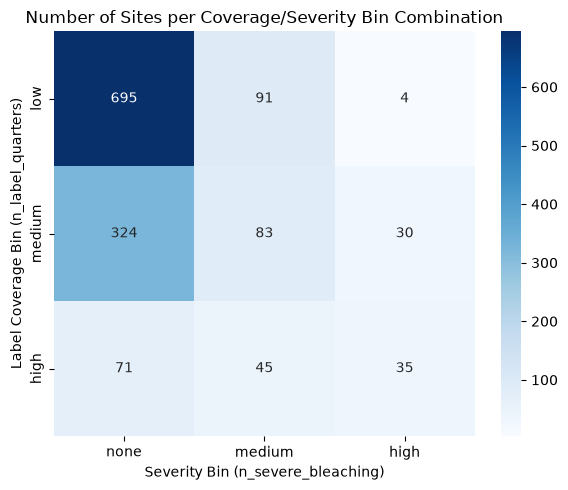

In [132]:
import seaborn as sns


bin_counts = pd.crosstab(split_sites["label_coverage_bin"], split_sites["severity_bin"])

plt.figure(figsize=(6, 5))
sns.heatmap(bin_counts, annot=True, fmt="d", cmap="Blues")
plt.title("Number of Sites per Coverage/Severity Bin Combination")
plt.xlabel("Severity Bin (n_severe_bleaching)")
plt.ylabel("Label Coverage Bin (n_label_quarters)")
plt.tight_layout()
plt.show()

In [133]:
label_coverage_counts = split_sites["label_coverage_bin"].value_counts(sort=False)
print(label_coverage_counts)
print("\nNormalized sites per label coverage bin:")
print(label_coverage_counts / label_coverage_counts.sum())


print(split_sites["severity_bin"].value_counts(sort=False))
print("\nNormalized sites per severity bin:")
severity_counts = split_sites["severity_bin"].value_counts(sort=False)
print(severity_counts / severity_counts.sum())


label_coverage_bin
low       790
medium    437
high      151
Name: count, dtype: int64

Normalized sites per label coverage bin:
label_coverage_bin
low       0.573295
medium    0.317126
high      0.109579
Name: count, dtype: float64
severity_bin
none      1090
medium     219
high        69
Name: count, dtype: int64

Normalized sites per severity bin:
severity_bin
none      0.791001
medium    0.158926
high      0.050073
Name: count, dtype: float64


## Spatial block split assignment balanced on 4 classes

In [134]:
# group nearby sites into spatial blocks so they always end up in the same split
split_sites["spatial_block"] = (
    (split_sites["lat"] // SPATIAL_BLOCK_DEG).astype(int).astype(str)
    + "_"
    + (split_sites["lon"] // SPATIAL_BLOCK_DEG).astype(int).astype(str)
)
print(f"Sites: {len(split_sites)}, spatial blocks: {split_sites['spatial_block'].nunique()}")
split_sites[["site_id", "lat", "lon", "spatial_block"]].head(10)

Sites: 1378, spatial blocks: 143


,site_id,lat,lon,spatial_block
0,0098fca8-d6c6-4859-ba06-74d5207a44ca,10.121028,99.834861,10_99
1,009b5024-f412-4606-b016-497c0eb48ae2,-8.340278,116.028611,-9_116
2,00ab83f6-ad6e-4b56-86c8-971a8abcc19d,19.643667,-156.015667,19_-157
3,00b56bab-1879-4d7d-bbc7-f5ae3ce3d541,22.829722,121.188889,22_121
4,0129d04a-00f3-4847-a0cc-bbc90dcc9813,18.365951,-68.848883,18_-69
5,0155a127-73ba-44ff-817f-7343b05f8c7f,-8.676667,115.520278,-9_115
6,017b73b2-2567-44c8-ad06-fb703941fd05,2.218306,104.149833,2_104
7,01a8ff52-ee72-4576-924b-1819ba49eda8,-16.765861,179.964472,-17_179
8,01c91a51-8bfa-450e-b174-7a3555e08d21,19.690417,-156.039417,19_-157
9,025087b9-09e6-4978-a3de-44d78cd70b7f,11.338389,-60.550028,11_-61


In [135]:
# Count the number of sites assigned to each spatial block
sites_per_block = (
    split_sites["spatial_block"]
    .value_counts()
    .sort_index()
)

print(f"Number of different spatial blocks: {sites_per_block.size}")
print("\nNumber of sites per spatial block:")
print(sites_per_block.rename("n_sites"))


Number of different spatial blocks: 143

Number of sites per spatial block:
spatial_block
-10_119      1
-13_45       4
-14_48      16
-17_-152    19
-17_-180     1
            ..
7_98         1
9_-76        3
9_-77        9
9_-80        1
9_-83        4
Name: n_sites, Length: 143, dtype: int64


In [136]:
# class conversion
split_labels_long["class"] = split_labels_long["bleaching_percent"].map(bleaching_percent_to_class) 

# Count quarters per class for each spatial block
block_groups = split_sites.groupby("spatial_block")
block_class_counts = {}  

for block_name in block_groups.groups.keys():
    # Get all sites in this block
    block_sites = block_groups.get_group(block_name)["site_id"].tolist()
    
    # Get all labeled quarters for these sites
    block_quarters = split_labels_long[split_labels_long["site_id"].isin(block_sites)]
    
    # Count quarters per class
    class_counts = {
        0.0: (block_quarters["class"] == 0.0).sum(),
        1.0: (block_quarters["class"] == 1.0).sum(),
        2.0: (block_quarters["class"] == 2.0).sum(),
        3.0: (block_quarters["class"] == 3.0).sum(),
    }
    block_class_counts[block_name] = class_counts

# Calculate overall class distribution
overall_class_counts = {
    0.0: (split_labels_long["class"] == 0.0).sum(),
    1.0: (split_labels_long["class"] == 1.0).sum(),
    2.0: (split_labels_long["class"] == 2.0).sum(),
    3.0: (split_labels_long["class"] == 3.0).sum(),
}
total_quarters = sum(overall_class_counts.values())

print("Overall class distribution:")
for cls in [0.0, 1.0, 2.0, 3.0]:
    count = overall_class_counts[cls]
    pct = 100.0 * count / total_quarters 
    print(f"  Class {int(cls)}: {count} quarters ({pct}%)")

# Assign blocks to splits using greedy balancing on class distribution
rng = np.random.default_rng(SPLIT_RANDOM_SEED)
block_order = list(block_groups.groups.keys())
rng.shuffle(block_order)

# Calculate target class counts for each split
target_class_counts = {
    name: {cls: frac * overall_class_counts[cls] for cls in [0.0, 1.0, 2.0, 3.0]}
    for name, frac in SPLIT_TARGET_FRACTIONS.items()
}

# Initialize current counts per split
current_class_counts = {
    name: {cls: 0.0 for cls in [0.0, 1.0, 2.0, 3.0]}
    for name in SPLIT_TARGET_FRACTIONS
}
block_to_split = {}

# Greedy assignment: for each block, assign to the split with the largest class deficit
for block_name in block_order:
    block_class = block_class_counts[block_name]
    n_sites_in_block = len(block_groups.get_group(block_name))
    
    # Calculate deficit score for each split
    # Deficit = sum of class-wise relative deficits (normalized per class to avoid large classes dominating)
    scores = {}
    for split_name in SPLIT_TARGET_FRACTIONS:
        deficit_score = 0.0
        for cls in [0.0, 1.0, 2.0, 3.0]:
            target = target_class_counts[split_name][cls]
            current = current_class_counts[split_name][cls]
            # Normalize by target to give equal weight to each class
            if target > 0: # if class doesnt exist like in small test ds
                deficit_score += (target - current) / target
        scores[split_name] = deficit_score
    
    # Assign block to split with highest deficit score
    chosen_split = max(scores, key=scores.get)
    block_to_split[block_name] = chosen_split
    
    # Update current counts
    for cls in [0.0, 1.0, 2.0, 3.0]:
        current_class_counts[chosen_split][cls] += block_class[cls]

# Map each site to its assigned split based on its spatial_block
split_sites["split"] = split_sites["spatial_block"].map(block_to_split)

split_sites["split"].value_counts()

Overall class distribution:
  Class 0: 3055 quarters (69.19592298980747%)
  Class 1: 984 quarters (22.2876557191393%)
  Class 2: 330 quarters (7.474518686296716%)
  Class 3: 46 quarters (1.0419026047565119%)


split
train    884
test     260
val      234
Name: count, dtype: int64

In [137]:
splits_out = split_sites.copy()
splits_out["sid"] = "SID_" + splits_out["site_id"].astype(str)  # matches labels.parquet index
splits_out = splits_out[[
    "site_id", "sid", "spatial_block", "n_label_quarters", "n_severe_bleaching",
    "label_coverage_bin", "severity_bin", "split",
]]

splits_out.to_parquet(r"C:\Users\ohlle\OneDrive\Dokumente\TUM\Master\Research Practice\Scripts\Labels\splits.parquet", index=False)
splits_out.head()

,site_id,sid,spatial_block,n_label_quarters,n_severe_bleaching,label_coverage_bin,severity_bin,split
0,0098fca8-d6c6-4859-ba06-74d5207a44ca,SID_0098fca8-d6c6-4859-ba06-74d5207a44ca,10_99,4,0,medium,none,test
1,009b5024-f412-4606-b016-497c0eb48ae2,SID_009b5024-f412-4606-b016-497c0eb48ae2,-9_116,2,0,low,none,train
2,00ab83f6-ad6e-4b56-86c8-971a8abcc19d,SID_00ab83f6-ad6e-4b56-86c8-971a8abcc19d,19_-157,1,0,low,none,val
3,00b56bab-1879-4d7d-bbc7-f5ae3ce3d541,SID_00b56bab-1879-4d7d-bbc7-f5ae3ce3d541,22_121,1,0,low,none,train
4,0129d04a-00f3-4847-a0cc-bbc90dcc9813,SID_0129d04a-00f3-4847-a0cc-bbc90dcc9813,18_-69,4,1,medium,medium,train


In [138]:
train_site_ids = splits_out.loc[
    splits_out["split"] == "train",
    "sid",
]

pure_class_0_train = pure_class_0 & labels.index.isin(train_site_ids)

print(f"Pure class-0/NaN training sites: {pure_class_0_train.sum()}")

Pure class-0/NaN training sites: 361


## Statistics

In [139]:
# Class 3 (severe bleaching) analysis because high val/test metrics difference

# For each site, count class 3 quarters
site_class3_counts = split_labels_long[split_labels_long['class'] == 3.0].groupby('site_id').size()
site_class3_info = pd.DataFrame({
    'site_id': site_class3_counts.index,
    'n_class3_quarters': site_class3_counts.values
})

# Add split and spatial block info
site_class3_info = site_class3_info.merge(
    splits_out[['site_id', 'split', 'spatial_block', 'sid']],
    on='site_id',
    how='left'
)
site_class3_info = site_class3_info.sort_values(['split', 'n_class3_quarters'], ascending=[True, False])

print("All sites that contain class 3:")
site_class3_display = site_class3_info[['sid', 'split', 'spatial_block', 'n_class3_quarters']].copy()
site_class3_display.columns = ['SID', 'Split', 'Spatial_Block', 'N_Class3_Quarters']
site_class3_display

All sites that contain class 3:


,SID,Split,Spatial_Block,N_Class3_Quarters
2,SID_0a962840-c759-495b-987c-30350b44d730,test,14_-62,1
4,SID_0d1a6d4e-1daa-47c4-be03-1a9a18ebbde6,test,14_-61,1
33,SID_b6af0637-81ae-46c3-b7ec-af2e4e490c9e,test,4_118,1
34,SID_b9fdfaf4-b118-40a3-b108-43e1f8ff4cb1,test,14_-62,1
41,SID_fad05a1d-4dbc-4d58-b034-a803b2819b3a,test,14_-61,1
6,SID_0e404fbd-9cd0-4d12-bf5c-c71e0c144deb,train,5_102,2
19,SID_68a19a08-e59b-4068-b37f-2969fbea5ebc,train,5_102,2
0,SID_0129d04a-00f3-4847-a0cc-bbc90dcc9813,train,18_-69,1
1,SID_09c1bb81-422e-4a34-8b5d-b43c6ebaa69d,train,-17_145,1
3,SID_0cc9d5cf-4278-4781-bcb5-3fc3e093c5ea,train,-9_116,1


In [140]:
print(f"\nTotal sites: {len(splits_out)}")
print(f"Total labeled quarters: {total_quarters}\n")

# class distribution for each split
split_stats = {}
for split_name in ["train", "val", "test"]:
    split_sites_list = splits_out[splits_out["split"] == split_name]["site_id"].tolist()
    split_quarters = split_labels_long[split_labels_long["site_id"].isin(split_sites_list)]
    
    n_sites = len(split_sites_list)
    n_quarters = len(split_quarters)
    
    class_counts_split = {
        0.0: (split_quarters["class"] == 0.0).sum(),
        1.0: (split_quarters["class"] == 1.0).sum(),
        2.0: (split_quarters["class"] == 2.0).sum(),
        3.0: (split_quarters["class"] == 3.0).sum(),
    }
    
    split_stats[split_name] = {
        "n_sites": n_sites,
        "n_quarters": n_quarters,
        "class_counts": class_counts_split,
    }
    
    # Spatial blocks and class 3 sites
    split_data = splits_out[splits_out['split'] == split_name]
    n_blocks = split_data['spatial_block'].nunique()
    n_class3_sites = len(site_class3_info[site_class3_info['site_id'].isin(split_sites_list)])
    
    print(f"{split_name.upper()}:")
    print(f"  Sites: {n_sites} ({100.0 * n_sites / len(splits_out):.1f}%)")
    print(f"  Spatial blocks: {n_blocks}")
    print(f"  Class 3 sites: {n_class3_sites}")
    print(f"  Total quarters: {n_quarters}")
    for cls in [0.0, 1.0, 2.0, 3.0]:
        count = class_counts_split[cls]
        pct = 100.0 * count / n_quarters 
        print(f"    Class {int(cls)}: {count} quarters ({pct:5.1f}%)")


Total sites: 1378
Total labeled quarters: 4415

TRAIN:
  Sites: 884 (64.2%)
  Spatial blocks: 86
  Class 3 sites: 30
  Total quarters: 2899
    Class 0: 1930 quarters ( 66.6%)
    Class 1: 698 quarters ( 24.1%)
    Class 2: 239 quarters (  8.2%)
    Class 3: 32 quarters (  1.1%)
VAL:
  Sites: 234 (17.0%)
  Spatial blocks: 29
  Class 3 sites: 9
  Total quarters: 713
    Class 0: 537 quarters ( 75.3%)
    Class 1: 120 quarters ( 16.8%)
    Class 2: 47 quarters (  6.6%)
    Class 3: 9 quarters (  1.3%)
TEST:
  Sites: 260 (18.9%)
  Spatial blocks: 28
  Class 3 sites: 5
  Total quarters: 803
    Class 0: 588 quarters ( 73.2%)
    Class 1: 166 quarters ( 20.7%)
    Class 2: 44 quarters (  5.5%)
    Class 3: 5 quarters (  0.6%)


# Data Vizualisation

In [141]:
total_site_ids = pop["site_id"].nunique()
site_ids_depth_10m_or_less = pop.loc[
    pop["depth (m)"] <= 10, "site_id"
].nunique()

print(f"Total unique site IDs: {total_site_ids}")
print(f"Unique site IDs with depth <= 10 m: {site_ids_depth_10m_or_less}") # ACA benthic map max = 10m depth

Total unique site IDs: 1378
Unique site IDs with depth <= 10 m: 1270


## samples per country and regions

In [142]:

country_counts = (
    pop.groupby("country")
    .size()
    .reset_index(name="n_samples")
    .sort_values("n_samples", ascending=False)
)

country_region_counts = (
    pop.groupby(["country", "region"])
    .size()
    .unstack(fill_value=0)
    .reset_index()
)

country_counts = country_counts.merge(country_region_counts, on="country", how="left")


country_counts_df = pd.DataFrame(country_counts)
country_counts_df.head(20)
# -> Indo-Pacific region has the most samples

,country,n_samples,Arabian Gulf,Atlantic,East Pacific,Hawaii,Indo-Pacific,Red Sea
0,Malaysia,2200,0,0,0,0,2200,0
1,Indonesia,700,0,0,0,0,700,0
2,Australia,603,0,0,0,0,603,0
3,French Polynesia,322,0,0,0,0,322,0
4,Maldives,182,0,0,0,0,182,0
5,Egypt,163,0,0,0,0,0,163
6,"Taiwan, Province of China",133,0,0,0,0,133,0
7,Jamaica,102,0,102,0,0,0,0
8,United States of America,99,0,11,0,88,0,0
9,Colombia,62,0,61,1,0,0,0


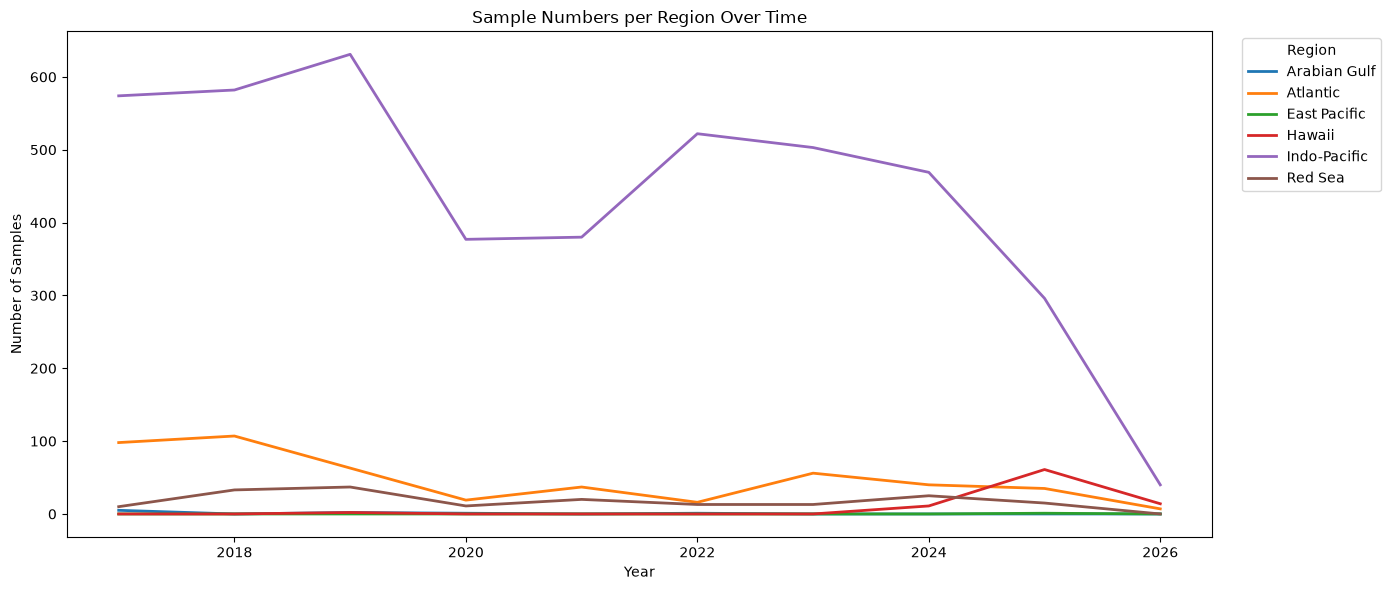

In [143]:
import matplotlib.pyplot as plt

# count samples per year and region
region_quarter_counts = (
    pop.groupby(["year", "region"])
    .size()
    .unstack(fill_value=0)
    .sort_index()
)


ax = region_quarter_counts.plot(figsize=(14, 6), linewidth=2)

ax.set_title("Sample Numbers per Region Over Time")
ax.set_xlabel("Year")
ax.set_ylabel("Number of Samples")
ax.legend(title="Region", bbox_to_anchor=(1.02, 1), loc="upper left")

plt.tight_layout()
plt.show()

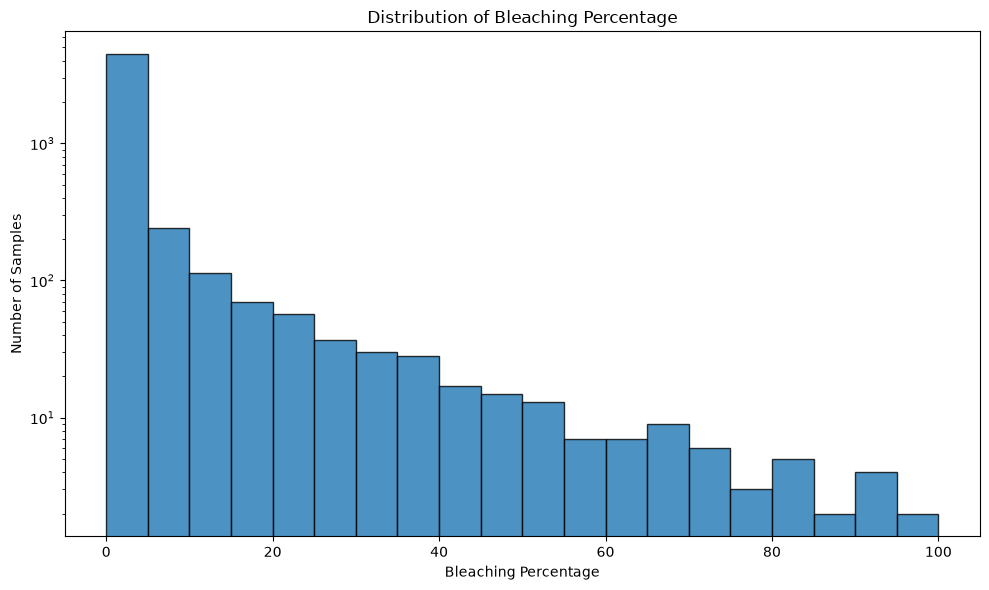

In [144]:
ax = pop["bleaching_percent"].plot(
    kind="hist",
    bins=20,                # adjust bin count for more/less detail
    figsize=(10, 6),
    edgecolor="black",
    alpha=0.8
)

plt.yscale("log")  
ax.set_title("Distribution of Bleaching Percentage")
ax.set_xlabel("Bleaching Percentage")
ax.set_ylabel("Number of Samples")

plt.tight_layout()
plt.show()
#->many samples with low bleaching, few with high bleaching

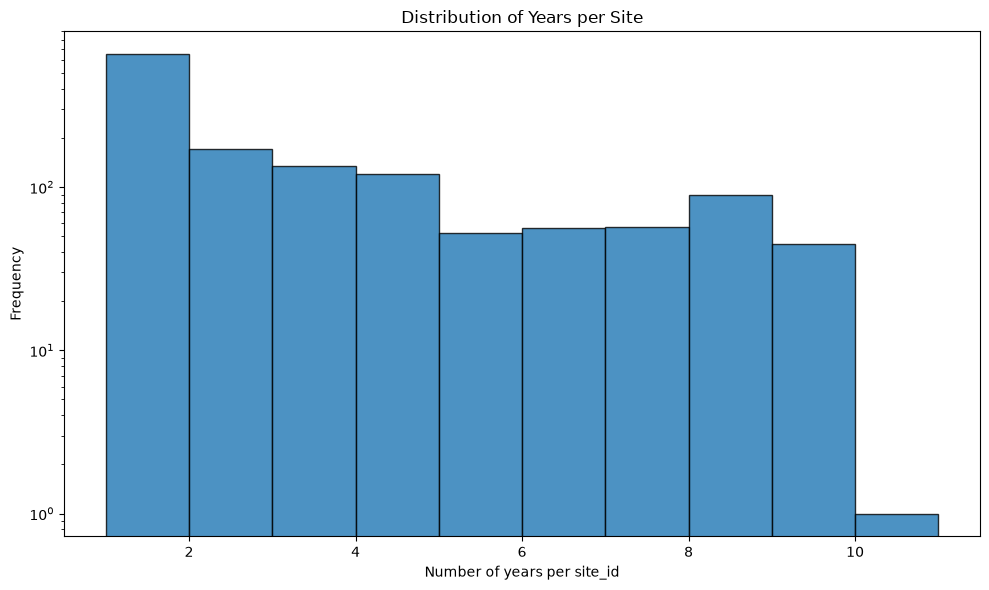

In [145]:

quarters_per_site = pop.groupby("site_id")["year"].nunique()

# Integer bins so each bar represents one "number of years"
bins = range(1, int(quarters_per_site.max()) + 2) 

ax = quarters_per_site.plot(
    kind="hist",
    bins=bins,
    figsize=(10, 6),
    edgecolor="black",
    alpha=0.8
)

ax.set_title("Distribution of Years per Site")
ax.set_xlabel("Number of years per site_id")
ax.set_ylabel("Frequency")
ax.set_yscale("log")

plt.tight_layout()
plt.show()

## Boxplot

In [146]:
import seaborn as sns
import matplotlib.pyplot as plt

In [147]:
boxplot_data = pop[pop["bleaching_percent"] > 0].copy()

([0, 1, 2, 3, 4, 5, 6, 7, 8, 9],
 [Text(0, 0, '2017'),
  Text(1, 0, '2018'),
  Text(2, 0, '2019'),
  Text(3, 0, '2020'),
  Text(4, 0, '2021'),
  Text(5, 0, '2022'),
  Text(6, 0, '2023'),
  Text(7, 0, '2024'),
  Text(8, 0, '2025'),
  Text(9, 0, '2026')])

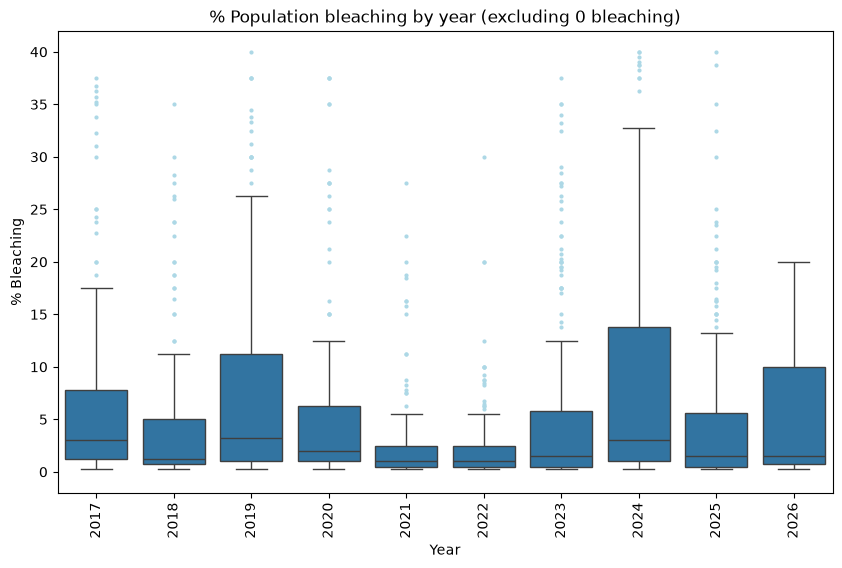

In [148]:
plt.figure(figsize=(10, 6))
flierprops = dict(marker='o', markersize=2, linestyle='none', markeredgecolor='lightblue', markerfacecolor='lightblue')
ax = sns.boxplot(x='year', y='bleaching_percent', data=boxplot_data, showfliers=True, flierprops=flierprops)
plt.title('% Population bleaching by year (excluding 0 bleaching)')
plt.xlabel('Year')
plt.ylabel('% Bleaching')
ax.set_ylim(-2, 42)
plt.xticks(rotation=90)

In [149]:
pop_indo_pacific = pop[pop["region"].isin(["Indo-Pacific"])].copy()
boxplot_data = pop_indo_pacific[pop_indo_pacific["bleaching_percent"] > 0]

([0, 1, 2, 3, 4, 5, 6, 7, 8, 9],
 [Text(0, 0, '2017'),
  Text(1, 0, '2018'),
  Text(2, 0, '2019'),
  Text(3, 0, '2020'),
  Text(4, 0, '2021'),
  Text(5, 0, '2022'),
  Text(6, 0, '2023'),
  Text(7, 0, '2024'),
  Text(8, 0, '2025'),
  Text(9, 0, '2026')])

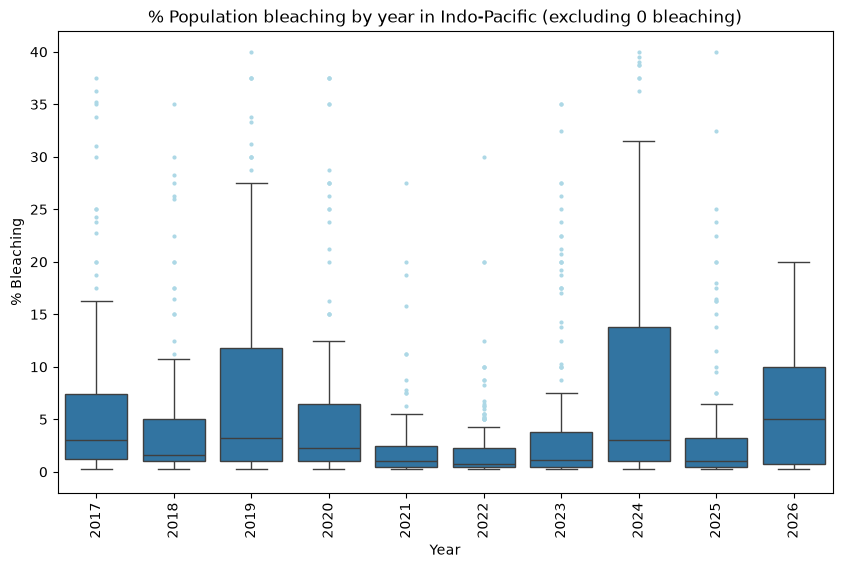

In [150]:
plt.figure(figsize=(10, 6))
flierprops = dict(marker='o', markersize=2, linestyle='none', markeredgecolor='lightblue', markerfacecolor='lightblue')
ax = sns.boxplot(x='year', y='bleaching_percent', data=boxplot_data, showfliers=True, flierprops=flierprops)
plt.title('% Population bleaching by year in Indo-Pacific (excluding 0 bleaching)')
plt.xlabel('Year')
plt.ylabel('% Bleaching')
ax.set_ylim(-2, 42)
plt.xticks(rotation=90)

## ONI 3-Month Mean Time Series (2002-2026)

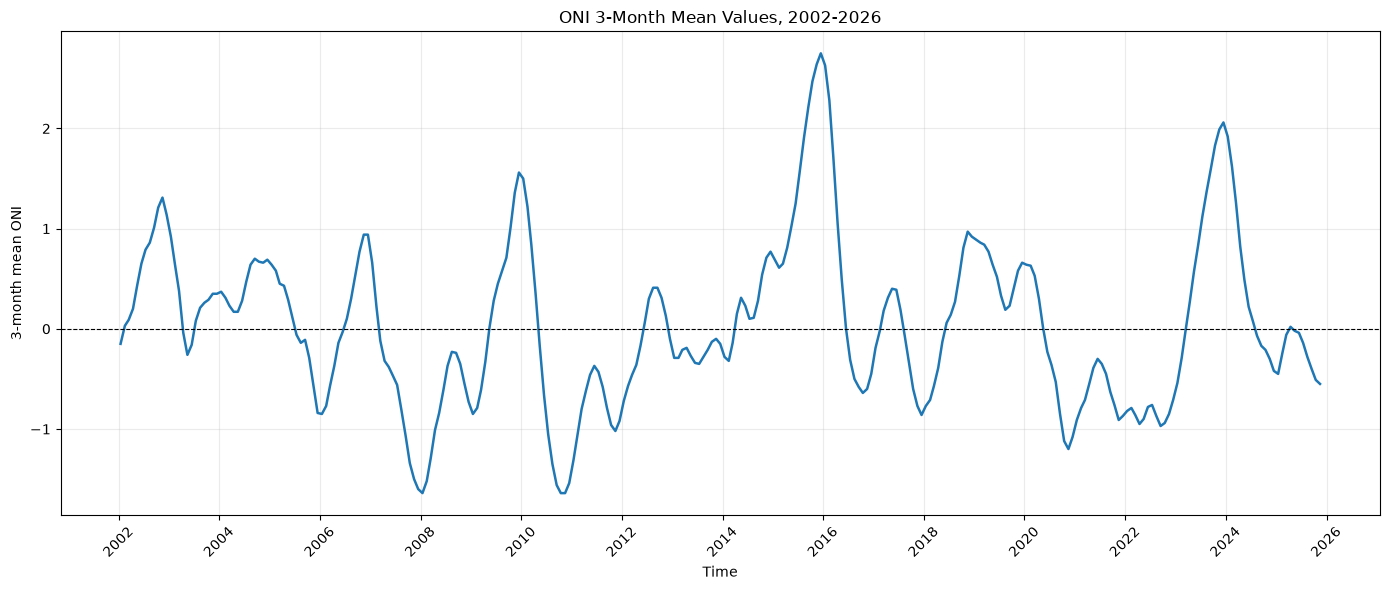

,season_start_year,season,oni_3month_mean,time
227,2001,DJF,-0.15,2002-01-15
263,2001,JFM,0.03,2002-02-15
299,2001,FMA,0.09,2002-03-15
335,2001,MAM,0.20,2002-04-15
371,2001,AMJ,0.43,2002-05-15


In [74]:
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates

oni_path = Path(r"C:\Users\ohlle\OneDrive\Dokumente\TUM\Master\Research Practice\Docs\3-Month Mean ONI values.xlsx")
season_order = ["JJA", "JAS", "ASO", "SON", "OND", "NDJ", "DJF", "JFM", "FMA", "MAM", "AMJ", "MJJ"]

oni = pd.read_excel(oni_path)
oni.columns = [str(column).strip().upper() for column in oni.columns]

season_column = "SEASON"
missing_columns = [season for season in season_order if season not in oni.columns]
if season_column not in oni.columns or missing_columns:
    raise ValueError(f"Missing required columns: {[season_column, *missing_columns]}")

oni["season_start_year"] = pd.to_numeric(
    oni[season_column].astype(str).str.extract(r"(\d{4})")[0],
    errors="coerce",
)
oni = oni.dropna(subset=["season_start_year"]).copy()
oni["season_start_year"] = oni["season_start_year"].astype(int)

oni_long = oni.melt(
    id_vars="season_start_year",
    value_vars=season_order,
    var_name="season",
    value_name="oni_3month_mean",
)
oni_long["oni_3month_mean"] = pd.to_numeric(oni_long["oni_3month_mean"], errors="coerce")
oni_long = oni_long.dropna(subset=["oni_3month_mean"]).copy()

# Each row spans JJA of the first year through MJJ of the following year.
season_month = {
    "JJA": 7, "JAS": 8, "ASO": 9, "SON": 10,
    "OND": 11, "NDJ": 12, "DJF": 1, "JFM": 2,
    "FMA": 3, "MAM": 4, "AMJ": 5, "MJJ": 6,
}
season_year_offset = {
    "JJA": 0, "JAS": 0, "ASO": 0, "SON": 0,
    "OND": 0, "NDJ": 0, "DJF": 1, "JFM": 1,
    "FMA": 1, "MAM": 1, "AMJ": 1, "MJJ": 1,
}

oni_long["season_order"] = oni_long["season"].map({season: index for index, season in enumerate(season_order)})
oni_long["plot_year"] = oni_long["season_start_year"] + oni_long["season"].map(season_year_offset)
oni_long["plot_month"] = oni_long["season"].map(season_month)
oni_long["time"] = pd.to_datetime({
    "year": oni_long["plot_year"],
    "month": oni_long["plot_month"],
    "day": 15,
})
oni_long = oni_long[oni_long["time"].between("2002-01-01", "2026-12-31")]
oni_long = oni_long.sort_values(["time", "season_order"])

plt.figure(figsize=(14, 6))
plt.plot(
    oni_long["time"],
    oni_long["oni_3month_mean"],
    color="tab:blue",
    linewidth=1.8,
)
plt.axhline(0, color="black", linestyle="--", linewidth=0.8)
plt.xlabel("Time")
plt.ylabel("3-month mean ONI")
plt.title("ONI 3-Month Mean Values, 2002-2026")
plt.grid(alpha=0.25)
plt.gca().xaxis.set_major_locator(mdates.YearLocator(2))
plt.gca().xaxis.set_major_formatter(mdates.DateFormatter("%Y"))
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

oni_long[["season_start_year", "season", "oni_3month_mean", "time"]].head()